In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, 
                             classification_report, RocCurveDisplay)

sns.set_theme(style="darkgrid")
print("Imports done ✅")

Imports done ✅


In [3]:
cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)
print(f"Loaded {df.shape[0]} rows ✅")

Loaded 500000 rows ✅


In [4]:
X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]}")
print(f"Test size:  {X_test.shape[0]}")

Train size: 400000
Test size:  100000


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Scaling done ✅")

Scaling done ✅


In [10]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

lr_auc = roc_auc_score(y_test, y_prob)
lr_acc = accuracy_score(y_test, y_pred)

print(f"Logistic Regression")
print(f"  Accuracy : {lr_acc:.4f}")
print(f"  AUC-ROC  : {lr_auc:.4f}")

Logistic Regression
  Accuracy : 0.6410
  AUC-ROC  : 0.6845


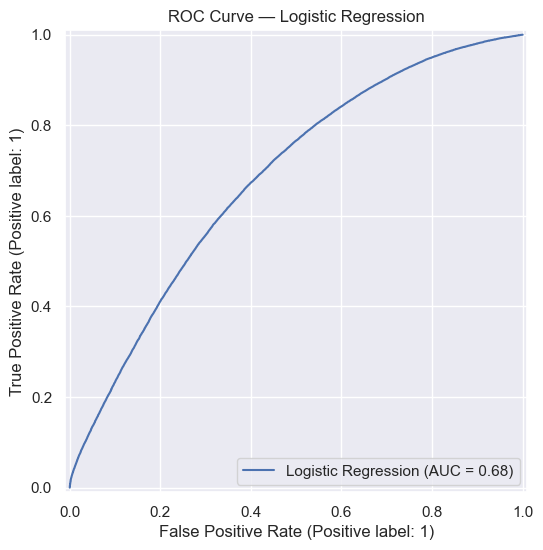

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, y_prob,    
    name=f"Logistic Regression", ax=ax)
ax.set_title("ROC Curve — Logistic Regression")
plt.savefig('../plots/roc_logistic_regression.png', dpi=150)
plt.show()

In [9]:
# n_estimators=100 is standard, n_jobs=-1 uses all CPU cores
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)  # no scaling needed for tree models

y_pred_rf = rf.predict(X_test)
y_prob_rf  = rf.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, y_prob_rf)
rf_acc = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest")
print(f"  Accuracy : {rf_acc:.4f}")
print(f"  AUC-ROC  : {rf_auc:.4f}")

Random Forest
  Accuracy : 0.7287
  AUC-ROC  : 0.8078


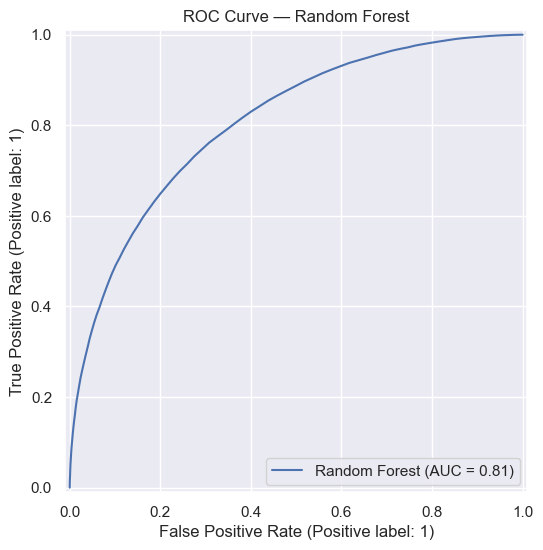

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, y_prob_rf, 
    name=f"Random Forest", ax=ax)
ax.set_title("ROC Curve — Random Forest")
plt.savefig('../plots/roc_random_forest.png', dpi=150)
plt.show()


In [9]:
import joblib

joblib.dump(lr, '../models/logistic_regression.pkl')
joblib.dump(rf, '../models/random_forest.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
print("Models saved ✅")

Models saved ✅


## Results: Baseline Models

| Model | Accuracy | AUC-ROC |
|-------|----------|---------|
| Logistic Regression | 0.6410 | 0.6845 |
| Random Forest | 0.7287 | 0.8078 |


## Observation: Baseline Results

Logistic Regression achieves an AUC-ROC of 0.6845, indicating it struggles 
with the non-linear decision boundary of this problem. Random Forest 
significantly outperforms it at 0.8078, confirming that tree-based 
ensemble methods handle the complex feature interactions in this dataset 
much better than a linear classifier.

This gap motivates the use of gradient boosting and neural networks 
in subsequent experiments.